# DataVerso 001 · Belo Horizonte's housing market in ITBI records

Belo Horizonte publishes records of property transactions reported for the municipal transfer tax, the ITBI (*Imposto sobre a Transmissão de Bens Imóveis*). The `pracadata/brazil-itbi` dataset on Hugging Face harmonises those records into one table spanning January 2008 to September 2026. The [project notes](README.md) describe the pinned input, attribution and publication checks.

The notebook asks four questions about houses and apartments sold between 2016 and 2025:

1. Where in the city is a square metre most expensive?
2. How does price change with distance from the city centre?
3. How did real declared values and ITBI tax bases change after adjusting for property characteristics?
4. Do declared prices cluster on round numbers, and by how much?

Two limits apply throughout. Each record carries a **declared** value and a **tax base**. These are administrative measures, and the choice between them changes the answer to question 3. And the analysis is exploratory: filters and model specifications were chosen after looking at the data, so the intervals describe sampling uncertainty given those choices, not the uncertainty of the whole analytical path.

Code and prose are in English. Every figure is drawn twice, in Brazilian Portuguese and in English, and both versions are saved.

## 1. Setup

Install this project environment with `uv sync --project projects/001-bh-itbi` from the repository root, and select its `.venv/bin/python` as the notebook kernel. The house style is in `house_style.py`, beside this notebook, and registers the IBM Plex fonts kept in the repository's `fonts/` directory.

The first data run downloads the pinned Hugging Face dataset and base-map tiles, which are cached. Shared settings follow the imports. The round-number settings and figure text stay with their respective analyses.

In [2]:
from pathlib import Path

import contextily as ctx
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import statsmodels.api as sm
import statsmodels.formula.api as smf
from huggingface_hub import hf_hub_download
from IPython.display import display
from matplotlib import patheffects
from matplotlib.axes import Axes
from matplotlib.cm import ScalarMappable
from matplotlib.colors import BoundaryNorm, ListedColormap, to_rgb
from matplotlib.lines import Line2D
from matplotlib.patches import Patch
from matplotlib.ticker import FuncFormatter
from matplotlib.transforms import blended_transform_factory, offset_copy

from house_style import (
    ACCENT,
    AXIS,
    CONTEXT,
    INK,
    LANDSCAPE_DPI,
    LANDSCAPE_SIZE,
    MARGIN,
    MUTED,
    PAPER,
    RC_PARAMS,
    SOCIAL_SIZE,
    format_brl,
    frame,
    number_formatter,
    register_fonts,
    style_axes,
)

In [3]:
REPO_ID = "pracadata/brazil-itbi"
FILENAME = "data/belo_horizonte_transactions.parquet"
# Pinned dataset commit, so the notebook keeps reading the same file
# even if the dataset is updated later.
REVISION = "5908d77ed56fc9adb6dbafaf2cb38f34245bcd76"
START_YEAR, END_YEAR = 2016, 2025

# Output
LANGUAGES = ("pt", "en")
OUTPUT_DIR = Path("figures")
TILE_CACHE = Path("tile_cache")

# Footer texts
SOURCE = {
    "pt": "Prefeitura de Belo Horizonte (ITBI), via pracadata/brazil-itbi.",
    "en": "Belo Horizonte City Hall (ITBI), via pracadata/brazil-itbi.",
}

# Section 4.1: price map
PRACA_SETE = (-19.9191, -43.9386)  # (lat, lon)
MAP_YEAR = 2023
WEB_MERCATOR_RADIUS = 6_378_137.0
BASEMAP = ctx.providers.Esri.WorldTopoMap
BASEMAP_ZOOM = 12
TILE_SATURATION = 0.5  # 1 keeps the tiles' colours, 0 is greyscale
TILE_STRENGTH = 0.6  # 1 keeps the tiles as they are, 0 is plain paper
SHOW_LANDMARKS = True  # switch off if they duplicate the base map's own labels
LANDMARKS = ["SAVASSI", "LOURDES", "BELVEDERE", "BURITIS", "CASTELO", "PAMPULHA"]
POINTS_PER_SALE = 5  # circle area per sale, in points²
SIZE_KEY_COUNTS = [1, 10, 50]
MAP_BOX = [0.05, 0.20, 0.90, 0.62]  # left, bottom, width, height as figure fractions

# Section 4.2: distance gradient
EARTH_RADIUS_KM = 6_371.0
MAX_DISTANCE_KM = 14
MIN_SALES_PER_BAND = 50  # in each period
GRADIENT_PERIODS = (
    (2016, 2018),
    (2019, 2021),
    (2022, 2025),
)  # first and last year, oldest first

# Section 5: hedonic model
MIN_SALES_PER_NEIGHBOURHOOD = 100
MEASURES = {"Declared value": "declared_m2_real", "Tax base": "tax_base_m2_real"}
FORMULA = (
    "np.log({value}) ~ np.log(built_area_m2)"
    " + C(building_age_band, Treatment('26_plus')) + C(property_type)"
    " + C(neighbourhood) + C(year)"
)

# Folders for the saved figures and for what is downloaded once and reused
for folder in (OUTPUT_DIR, TILE_CACHE):
    folder.mkdir(exist_ok=True)
ctx.set_cache_dir(str(TILE_CACHE))

### House style

Every figure is built on the same base, meant to be (potentially) reused in later DataVerso posts:

- Header: a short accent bar, a serif title that states the finding in one line, and a one-sentence subtitle saying what is measured, where and when
- Plot: the unit is written once above the axis, gridlines are thin, a key under the subtitle names the encodings, values are labelled directly on the data, and colour is kept for what carries the argument: the accent colour for the main series, a light-to-dark ramp for ordered periods, separate hues for the parts of a breakdown and greys for context.
- Footer: a thin rule, then the source and the methodological note on separate lines, with the repository on the right.
- Baseline: the bottom axis line is drawn dark only when the axis starts at zero, so it never suggests a zero that is not there.

Margins and text sizes are set in points. `frame`, from `house_style.py`, draws the header and footer and lets constrained layout fit the subplot grid between them. The map places its axes by hand in a fixed box. `add_key`, defined below, puts the key of a chart under the subtitle at the page margin; the map keeps its keys below it.

In [4]:
# Register the IBM Plex fonts and apply the house defaults to every new figure
register_fonts()
plt.rcParams.update(RC_PARAMS)


def add_key(
    ax: Axes,
    handles: list,
    labels: list[str],
    ncols: int | None = None,
    rise: float = 28.0,
    **options: object,
) -> None:
    """
    Name the encodings of a figure in a key under its subtitle, at the page margin.

    Each handle is a proxy artist that repeats one encoding exactly. The entries run in a
    single row unless ``ncols`` is given; a legend fills its columns from top to bottom.
    ``rise`` is the height of the key's lower edge above the axes, in points, so a second
    call with a smaller rise adds a row below the first. ``options`` go to ``ax.legend``.
    """
    fig = ax.get_figure(root=True)
    # A new legend replaces the axes' current one, so an earlier row is kept as an artist
    # add_artist clips it to the axes, which would hide it from constrained layout
    earlier = ax.get_legend()
    if earlier is not None:
        ax.add_artist(earlier)
        earlier.set_clip_on(False)
    # The key sits at the page margin (x in figure coordinates), ``rise`` points above the axes
    # (y in axes coordinates), so it clears the unit label; constrained layout makes room for it
    key_anchor = offset_copy(
        blended_transform_factory(fig.transFigure, ax.transAxes),
        fig=fig,
        y=rise,
        units="points",
    )
    ax.legend(
        handles,
        labels,
        loc="lower left",
        bbox_to_anchor=(MARGIN / (fig.get_figwidth() * 72), 1),
        bbox_transform=key_anchor,
        ncols=ncols or len(handles),
        frameon=False,
        fontsize=9,
        columnspacing=1.4,
        borderaxespad=0,
        borderpad=0,
        labelcolor=MUTED,
        **{"handlelength": 1.8, **options},
    )

## 2. Data

The values arrive as Python `Decimal` objects, which keep the exact cents of the source but make arithmetic slow and break some pandas operations. They are converted to floats once, here, so no later cell needs to convert them again.

In [5]:
# Download the file once (later runs read the local Hugging Face cache) and load it
parquet_path = hf_hub_download(
    repo_id=REPO_ID, repo_type="dataset", filename=FILENAME, revision=REVISION
)
transactions = pd.read_parquet(parquet_path)

# Decimal to float, dates to datetime, neighbourhood names to one spelling

NUMERIC_COLUMNS = [
    "value_declared_brl",
    "value_tax_base_brl",
    "value_declared_brl_real",
    "built_area_m2",
    "price_per_m2_brl",
    "price_per_m2_brl_real",
]
transactions[NUMERIC_COLUMNS] = transactions[NUMERIC_COLUMNS].astype(float)
transactions["transaction_date"] = pd.to_datetime(transactions["transaction_date"])
transactions["neighbourhood"] = transactions["neighbourhood"].str.strip().str.upper()

print(
    f"{len(transactions):,} transactions, "
    f"{transactions['transaction_date'].min():%b %Y} to "
    f"{transactions['transaction_date'].max():%b %Y}"
)

# Missingness of fields used for filtering, measurement or geocoding
inspection_columns = [
    "value_declared_brl",
    "value_tax_base_brl",
    "built_area_m2",
    "building_age_band",
    "geo_precision",
]
missing = transactions[inspection_columns].isna().sum().to_frame("Missing records")
display(missing.style.format("{:,}"))

516,725 transactions, Jan 2008 to Sep 2026


,Missing records
value_declared_brl,0
value_tax_base_brl,0
built_area_m2,"22,565"
building_age_band,"22,553"
geo_precision,0


### Which transactions are analysed

1. **Houses and apartments only.** Shops, offices, land and parking spaces follow different price logics.
2. **No value flag.** The source flags two kinds of unusable value: symbolic values (a nominal amount, typical of transfers between relatives) and guides that cover several units with one value, which makes the price of any single unit unknowable.
3. **A positive built area**, needed for the price per m².
4. **A declared price per m² between R$ 100 and R$ 200,000**, which trims extreme recorded values. The bounds may also exclude genuine transactions.
5. **Sold between 2016 and 2025**, a recent ten-year window in which every year is complete.

In [6]:
# Each rule is a boolean mask over all transactions, in the order it is applied
rules = {
    "House or apartment": transactions["property_type"].isin(["apartment", "house"]),
    "No value flag": transactions["value_flag"].isna(),
    "Positive built area": transactions["built_area_m2"] > 0,
    "Price per m² in [R$ 100, R$ 200,000]": transactions["price_per_m2_brl"].between(
        100, 200_000
    ),
    f"Sold {START_YEAR}–{END_YEAR}": transactions["year"].between(START_YEAR, END_YEAR),
}

# Apply the rules one after another, recording how many rows each one removes
kept = pd.Series(True, index=transactions.index)
funnel_rows = [{"rule": "All transactions", "kept": len(transactions), "removed": 0}]
for rule, mask in rules.items():
    removed = (kept & ~mask).sum()
    kept &= mask
    funnel_rows.append({"rule": rule, "kept": kept.sum(), "removed": removed})

# The analysed set, used by every later section
residential = transactions.loc[kept].copy()
display(pd.DataFrame(funnel_rows).set_index("rule").style.format("{:,}"))

,kept,removed
rule,,
All transactions,"516,725",0
House or apartment,"410,657","106,068"
No value flag,"400,444","10,213"
Positive built area,"400,412",32
"Price per m² in [R$ 100, R$ 200,000]","398,678","1,734"
Sold 2016–2025,"205,436","193,242"


## 3. Audit

### 3.1 Records per year

The source is not uniform over time. 2014 has far fewer records than its neighbours, for a reason the dataset does not document, and 2026 stops at the end of September. Neither year is in the analysed period, but both would distort any figure that spans the full series.

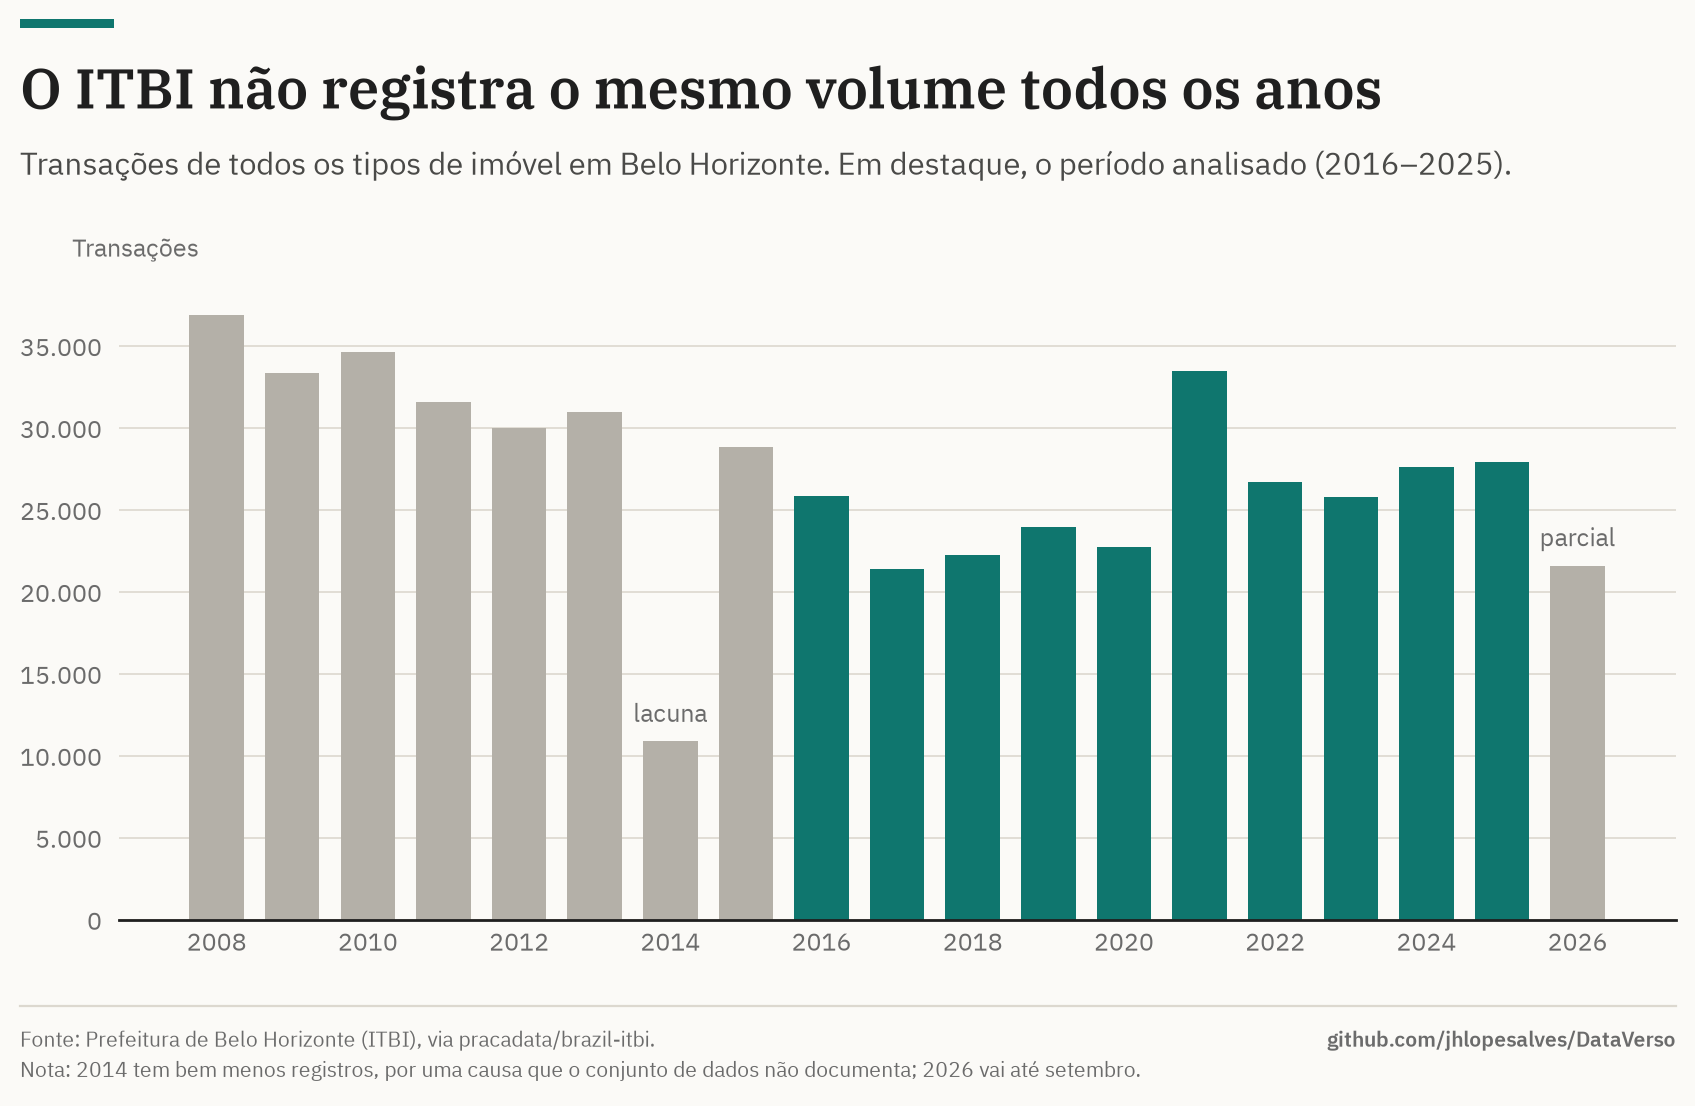

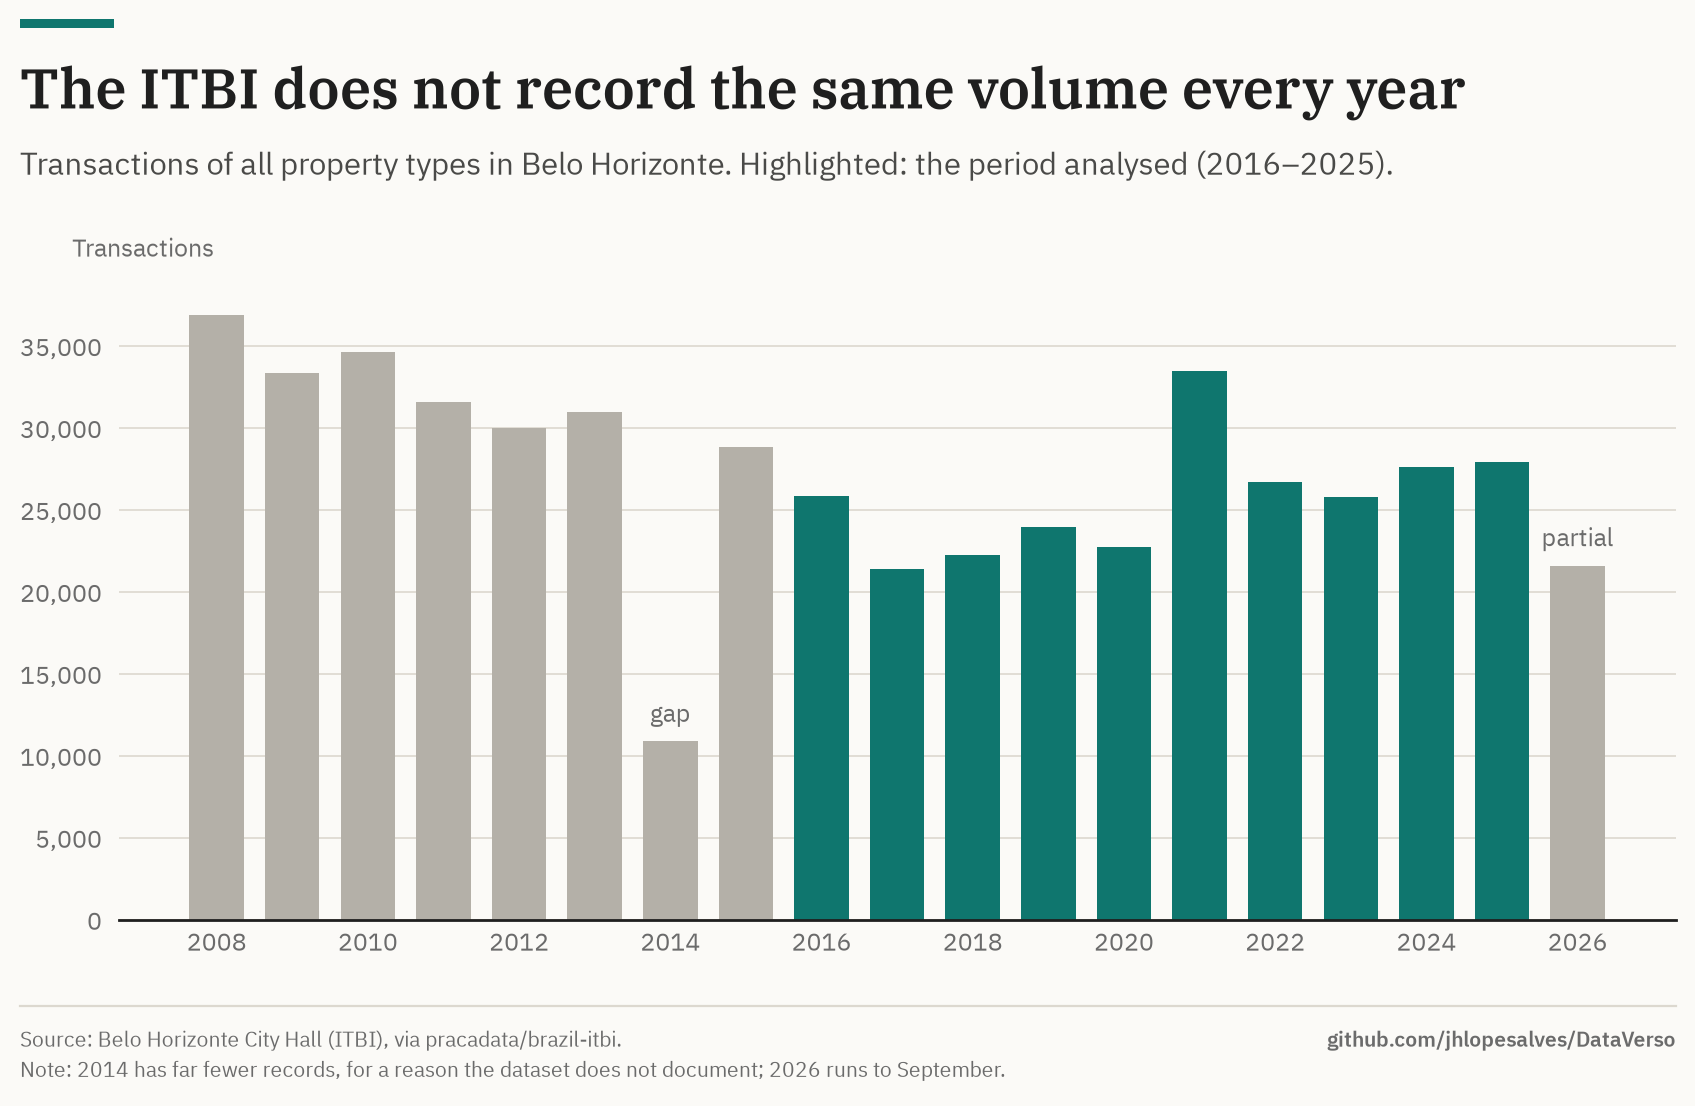

In [7]:
# Number of records in each year, and which years belong to the analysed period
records_per_year = transactions["year"].value_counts().sort_index()
in_window = records_per_year.index.to_series().between(START_YEAR, END_YEAR)

YEAR_TEXT = {
    "pt": {
        "title": "O ITBI não registra o mesmo volume todos os anos",
        "subtitle": f"Transações de todos os tipos de imóvel em Belo Horizonte. Em destaque, o período analisado ({START_YEAR}–{END_YEAR}).",
        "unit": "Transações",
        "gap": "lacuna",
        "partial": "parcial",
        "note": "2014 tem bem menos registros, por uma causa que o conjunto de dados não documenta; 2026 vai até setembro.",
    },
    "en": {
        "title": "The ITBI does not record the same volume every year",
        "subtitle": f"Transactions of all property types in Belo Horizonte. Highlighted: the period analysed ({START_YEAR}–{END_YEAR}).",
        "unit": "Transactions",
        "gap": "gap",
        "partial": "partial",
        "note": "2014 has far fewer records, for a reason the dataset does not document; 2026 runs to September.",
    },
}

for lang in LANGUAGES:
    text = YEAR_TEXT[lang]
    fig, ax = plt.subplots(figsize=LANDSCAPE_SIZE, dpi=LANDSCAPE_DPI)
    frame(
        fig,
        title=text["title"],
        subtitle=text["subtitle"],
        source=SOURCE[lang],
        note=text["note"],
        lang=lang,
    )

    # Bars: accent inside the analysed period, grey outside it
    ax.bar(
        records_per_year.index,
        records_per_year.to_numpy(),
        width=0.72,
        color=np.where(in_window, ACCENT, CONTEXT),
    )

    # The two years that need a word of explanation
    for label_year, label in [(2014, text["gap"]), (2026, text["partial"])]:
        ax.annotate(
            label,
            (label_year, records_per_year[label_year]),
            xytext=(0, 5),
            textcoords="offset points",
            ha="center",
            va="bottom",
            fontsize=9,
            color=MUTED,
        )

    # Bars start at zero, so the baseline is drawn dark
    style_axes(ax, text["unit"], zero_baseline=True)
    ax.tick_params(axis="x", length=0)
    ax.set_xticks(records_per_year.index[::2])
    ax.yaxis.set_major_formatter(number_formatter(lang))

    fig.savefig(OUTPUT_DIR / f"00_records_per_year_{lang}.png")
    plt.show()

### 3.2 Declared value against the tax base

Each record has two values: the value the parties declared and the tax base (*base de cálculo*) used to calculate ITBI. With a tolerance of R$1, no transaction in the analysed set has a declared value above its tax base. Over the whole period about half declare the base and half declare less. The share declaring less falls from around 70% in 2016–2018 to around 25% in 2023–2024.

Belo Horizonte's [published legislation](https://fazenda.pbh.gov.br/legislacao/formkey.asp?key=17) describes a municipal assessment or the declared value when higher. The [Superior Court of Justice's Tema 1.113](https://processo.stj.jus.br/repetitivos/temas_repetitivos/pesquisa.jsp?cod_tema_final=1113&cod_tema_inicial=1113&novaConsulta=true&tipo_pesquisa=T) presumes the declared value reflects market value and limits when the tax authority can set it aside. How those rules were applied to these records across 2016–2025 remains open. The observed gap between the two recorded values changes over time, which matters for the comparison in section 5.

In [8]:
# Classify each sale by how its declared value compares with its tax base
# A tolerance of R$ 1 absorbs rounding differences between the two values
gap = residential["value_declared_brl"] - residential["value_tax_base_brl"]
relation = pd.cut(
    gap,
    [-np.inf, -1, 1, np.inf],
    labels=["declared below base", "declared equals base", "declared above base"],
).rename("relation")

# Share of each class per year, plus one row for the whole period
# dropna=False keeps the "above base" column even though it is empty
base_check = pd.crosstab(residential["year"], relation, normalize="index", dropna=False)
base_check.loc[f"{START_YEAR}–{END_YEAR}"] = relation.value_counts(normalize=True)
display(base_check.style.format("{:.1%}"))

relation,declared below base,declared equals base,declared above base
year,,,
2016,69.0%,31.0%,0.0%
2017,72.6%,27.4%,0.0%
2018,69.6%,30.4%,0.0%
2019,66.4%,33.6%,0.0%
2020,54.6%,45.4%,0.0%
2021,45.7%,54.3%,0.0%
2022,35.4%,64.6%,0.0%
2023,27.3%,72.7%,0.0%
2024,24.5%,75.5%,0.0%


## 4. Where the money is

Both figures in this section place each sale on the map, so they use only transactions geocoded to the street face (`face_centroid`), the most precise location the source offers. Sales located only by postcode or neighbourhood centroid would pile up on a handful of points and distort both the map and the distances.

### 4.1 The price map

Street-face geocoding gives every sale on the same face the same coordinates: the 13,997 apartment sales of 2023 sit on only 4,920 distinct points. Drawn one dot per sale, about two thirds of them would be hidden under others. The map therefore draws one circle per street face, with its area proportional to the number of sales there and its colour set by their median declared price per m². Size shows where the market is active; colour shows what a square metre costs.

The map uses nominal values for a single year. The five colour classes use quintile cut points computed from individual sales. Each street-face median is assigned to one of those classes, so the numbers of faces and sales represented by each colour can differ. The largest circles are drawn first, so smaller ones remain visible on top of them.

The base map is the Esri World Topo Map, half desaturated and blended towards the paper colour, so relief, roads and water stay as context and the circles carry the colour.

In [9]:
# Apartment sales of the map year that are located to the street face
map_sales = residential.loc[
    (residential["geo_precision"] == "face_centroid")
    & (residential["property_type"] == "apartment")
    & (residential["year"] == MAP_YEAR)
].copy()

# The base-map tiles are in Web Mercator, so coordinates are projected to match
map_sales["x"] = WEB_MERCATOR_RADIUS * np.radians(map_sales["lon"])
map_sales["y"] = WEB_MERCATOR_RADIUS * np.log(
    np.tan(np.pi / 4 + np.radians(map_sales["lat"]) / 2)
)
centre_x = WEB_MERCATOR_RADIUS * np.radians(PRACA_SETE[1])
centre_y = WEB_MERCATOR_RADIUS * np.log(
    np.tan(np.pi / 4 + np.radians(PRACA_SETE[0]) / 2)
)

# One circle per street face: number of sales and their median price per m²
faces = (
    map_sales.groupby(["x", "y"])["price_per_m2_brl"]
    .agg(median="median", sales="size")
    .reset_index()
    .sort_values("sales", ascending=False)  # largest drawn first, small ones on top
)
# Neighbourhood labels sit at the median location of their own sales
landmark_points = (
    map_sales.groupby("neighbourhood")[["x", "y"]].median().reindex(LANDMARKS).dropna()
)

# Use transaction-level quintile cut points to classify street-face medians
price_edges = np.quantile(map_sales["price_per_m2_brl"], np.linspace(0, 1, 6))
class_cmap = ListedColormap(plt.cm.plasma_r(np.linspace(0.12, 0.92, 5)))
class_norm = BoundaryNorm(price_edges, class_cmap.N)

# Extent: the data's bounding box, widened to the shape of the map box so the base map fills the frame
box_ratio = (MAP_BOX[3] * SOCIAL_SIZE[1]) / (MAP_BOX[2] * SOCIAL_SIZE[0])
x_mid = (faces["x"].min() + faces["x"].max()) / 2
y_mid = (faces["y"].min() + faces["y"].max()) / 2
half_width = 0.52 * max(
    faces["x"].max() - faces["x"].min(),
    (faces["y"].max() - faces["y"].min()) / box_ratio,
)
half_height = half_width * box_ratio
x_limits = (x_mid - half_width, x_mid + half_width)
y_limits = (y_mid - half_height, y_mid + half_height)

# Base map: fetched once (then read from the tile cache) and softened
basemap_image, basemap_extent = ctx.bounds2img(
    x_limits[0],
    y_limits[0],
    x_limits[1],
    y_limits[1],
    zoom=BASEMAP_ZOOM,
    source=BASEMAP,
)
# Desaturate: mix each pixel with its own grey value
tiles = basemap_image[..., :3].astype(float)
tiles = TILE_SATURATION * tiles + (1 - TILE_SATURATION) * tiles.mean(
    axis=2, keepdims=True
)
# Fade: mix the result with the paper colour.
paper_rgb = 255 * np.array(to_rgb(PAPER))
basemap_soft = (TILE_STRENGTH * tiles + (1 - TILE_STRENGTH) * paper_rgb).astype(
    np.uint8
)

print(
    f"{len(map_sales):,} apartment sales in {MAP_YEAR} on {len(faces):,} street faces"
)
print("Quintile edges (R$/m²):", np.round(price_edges, -1))

13,997 apartment sales in 2023 on 4,920 street faces
Quintile edges (R$/m²): [  110.  2900.  3480.  4070.  4990. 17650.]


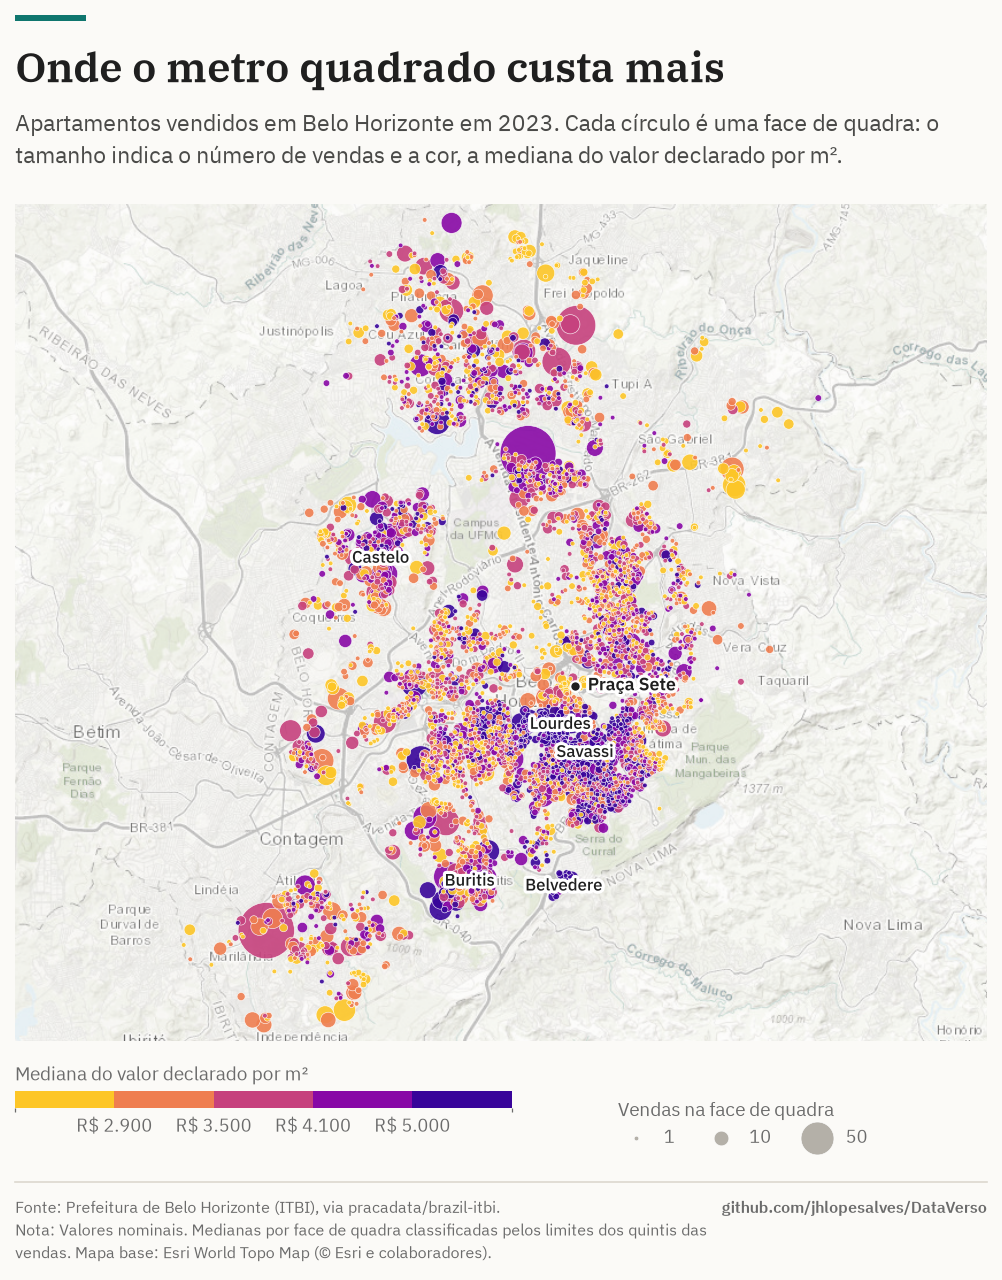

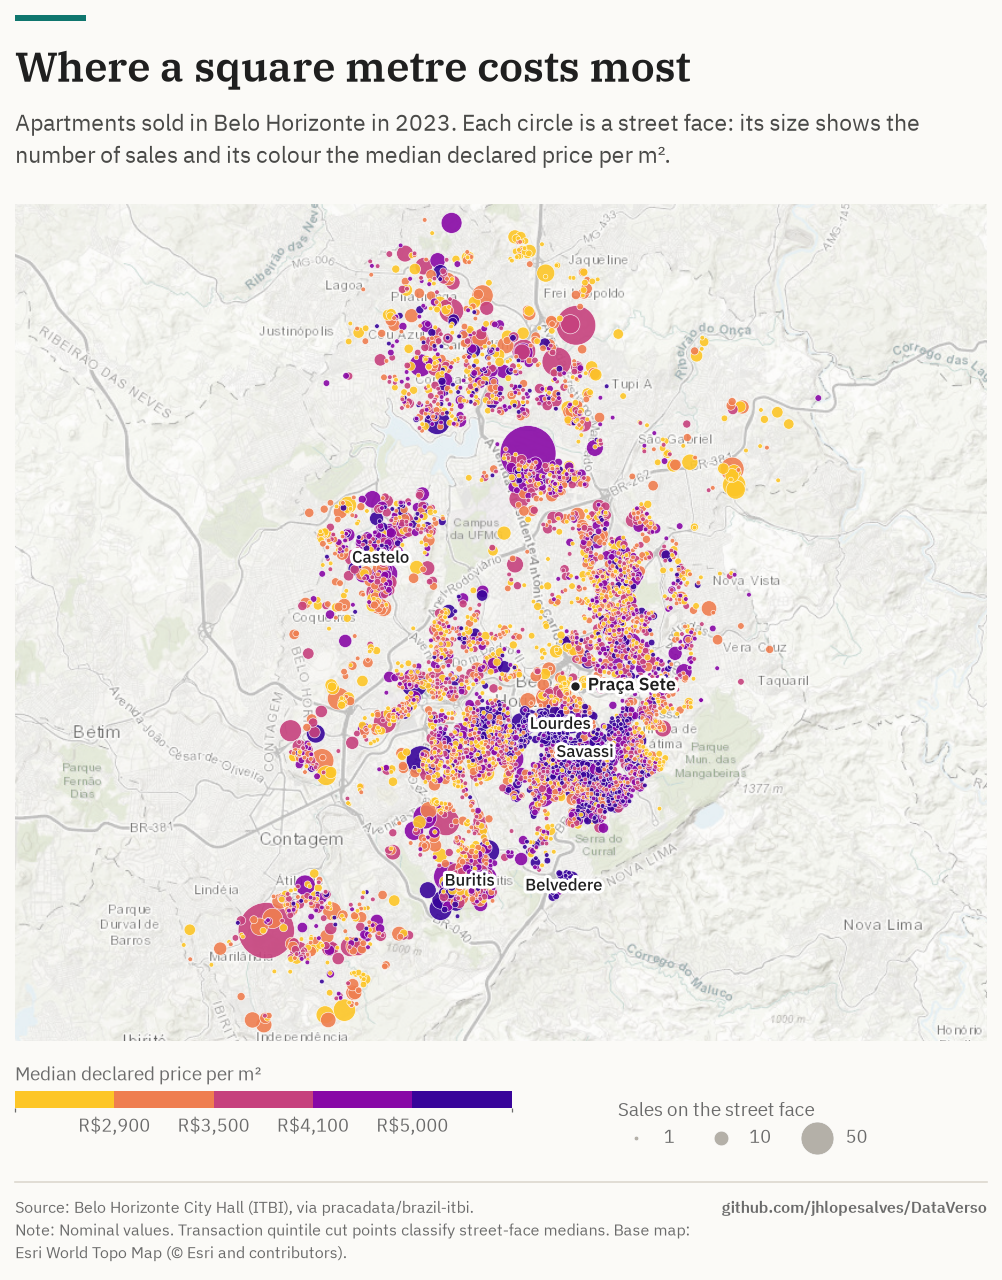

In [10]:
MAP_TEXT = {
    "pt": {
        "title": "Onde o metro quadrado custa mais",
        "subtitle": (
            f"Apartamentos vendidos em Belo Horizonte em {MAP_YEAR}. Cada círculo é uma face de quadra: o\n"
            "tamanho indica o número de vendas e a cor, a mediana do valor declarado por m²."
        ),
        "scale": "Mediana do valor declarado por m²",
        "size": "Vendas na face de quadra",
        "note": (
            "Valores nominais. Medianas por face de quadra classificadas pelos limites dos quintis das\n"
            "vendas. Mapa base: Esri World Topo Map (© Esri e colaboradores)."
        ),
    },
    "en": {
        "title": "Where a square metre costs most",
        "subtitle": (
            f"Apartments sold in Belo Horizonte in {MAP_YEAR}. Each circle is a street face: its size shows the\n"
            "number of sales and its colour the median declared price per m²."
        ),
        "scale": "Median declared price per m²",
        "size": "Sales on the street face",
        "note": (
            "Nominal values. Transaction quintile cut points classify street-face medians. Base map:\n"
            "Esri World Topo Map (© Esri and contributors)."
        ),
    },
}
# White outline behind the labels, so they stay legible over the map
halo = [patheffects.withStroke(linewidth=3, foreground="white")]

for lang in LANGUAGES:
    text = MAP_TEXT[lang]
    fig = plt.figure(figsize=SOCIAL_SIZE)
    frame(
        fig,
        title=text["title"],
        subtitle=text["subtitle"],
        source=SOURCE[lang],
        note=text["note"],
        lang=lang,
    )
    # The map has a fixed box, because the tiles were fetched for its shape. Its axes are
    # placed by hand, so the layout engine installed by frame() is switched off
    fig.set_layout_engine("none")
    ax = fig.add_axes(MAP_BOX)

    # Base map underneath, circles on top
    ax.imshow(basemap_soft, extent=basemap_extent, interpolation="bilinear", zorder=0)
    ax.scatter(
        faces["x"],
        faces["y"],
        s=POINTS_PER_SALE * faces["sales"],
        c=faces["median"],
        cmap=class_cmap,
        norm=class_norm,
        alpha=0.9,
        edgecolors="white",
        linewidths=0.3,
        zorder=2,
    )
    # imshow resets the limits to the tiles' extent, so they are set afterwards
    ax.set_xlim(x_limits)
    ax.set_ylim(y_limits)
    ax.set_aspect("equal")
    ax.axis("off")

    # Labels: Praça Sete with a marker, then the neighbourhood names
    ax.plot(
        centre_x,
        centre_y,
        marker="o",
        markersize=5,
        color=INK,
        markeredgecolor="white",
        zorder=3,
    )
    ax.annotate(
        "Praça Sete",
        (centre_x, centre_y),
        xytext=(6, -2),
        textcoords="offset points",
        fontsize=8.5,
        fontweight="semibold",
        color=INK,
        path_effects=halo,
        zorder=3,
    )
    if SHOW_LANDMARKS:
        for name, point in landmark_points.iterrows():
            ax.text(
                point["x"],
                point["y"],
                name.title(),
                fontsize=8,
                fontweight="medium",
                color=INK,
                ha="center",
                va="center",
                path_effects=halo,
                zorder=3,
            )

    # Colour key, below the map on the left: only the four inner edges, since
    # the outer two are the extremes of the data and carry no meaning
    cax = fig.add_axes([MAP_BOX[0], MAP_BOX[1] - 0.05, 0.46, 0.013])
    colourbar = fig.colorbar(
        ScalarMappable(norm=class_norm, cmap=class_cmap),
        cax=cax,
        orientation="horizontal",
        spacing="uniform",
        ticks=price_edges[1:-1],
    )
    colourbar.outline.set_visible(False)
    cax.tick_params(length=0, labelsize=8.5, colors=MUTED)
    cax.set_xticklabels(
        [format_brl(round(edge, -2), lang) for edge in price_edges[1:-1]]
    )
    cax.set_title(text["scale"], fontsize=9, color=MUTED, loc="left", pad=5)

    # Size key, below the map on the right: empty scatters give the legend its circles
    size_handles = [
        ax.scatter(
            [],
            [],
            s=POINTS_PER_SALE * count,
            color=CONTEXT,
            edgecolors="white",
            linewidths=0.3,
            label=str(count),
        )
        for count in SIZE_KEY_COUNTS
    ]
    size_key = fig.legend(
        handles=size_handles,
        title=text["size"],
        loc="lower left",
        bbox_to_anchor=(0.60, MAP_BOX[1] - 0.085),
        ncol=len(SIZE_KEY_COUNTS),
        frameon=False,
        fontsize=8.5,
        title_fontsize=9,
        labelcolor=MUTED,
        columnspacing=1.6,
        handletextpad=0.6,
        borderpad=0,
        alignment="left",
    )
    size_key.get_title().set_color(MUTED)

    fig.savefig(OUTPUT_DIR / f"01_price_map_{lang}.png")
    plt.show()

### 4.2 Price and distance from the centre

Each apartment sale of 2016–2025 is placed by its straight-line (haversine) distance from Praça Sete, the conventional centre of Belo Horizonte, and sales are grouped in 1 km bands. Each line follows the bands' median declared price per m² in one of three periods, 2016–2018, 2019–2021 and 2022–2025, adjusted by IPCA inflation to September 2026 reais. A band is shown in a period only if it has at least 50 sales in that period.

The periods are compared for the shape of the gradient rather than for price change: declared values also move with changes in how values are declared, a problem section 5 examines. The peak stays in the 1–2 km band in all three periods. The tables after the next cell list the neighbourhoods behind the first two bands in 2022–2025, so the reading of the peak rests on the places actually in it.

In [11]:
# Each compared period by year, named by its first and last year
period_of_year = {
    year: f"{first}–{last}"
    for first, last in GRADIENT_PERIODS
    for year in range(first, last + 1)
}
period_names = [f"{first}–{last}" for first, last in GRADIENT_PERIODS]

# Apartment sales of the compared periods that are located to the street face
gradient_sales = residential.loc[
    (residential["geo_precision"] == "face_centroid")
    & (residential["property_type"] == "apartment")
    & residential["year"].isin(period_of_year.keys())
].copy()
gradient_sales["period"] = gradient_sales["year"].map(period_of_year)

# Haversine (great-circle) distance from each sale to Praça Sete, in km
lat, lon = np.radians(gradient_sales["lat"]), np.radians(gradient_sales["lon"])
centre_lat, centre_lon = np.radians(PRACA_SETE)
haversine = (
    np.sin((lat - centre_lat) / 2) ** 2
    + np.cos(lat) * np.cos(centre_lat) * np.sin((lon - centre_lon) / 2) ** 2
)
gradient_sales["distance_km"] = 2 * EARTH_RADIUS_KM * np.arcsin(np.sqrt(haversine))
# Keep the sales within range and assign each to a 1 km band, named by its midpoint
gradient_sales = gradient_sales.loc[gradient_sales["distance_km"] < MAX_DISTANCE_KM]
gradient_sales["band_km"] = np.floor(gradient_sales["distance_km"]) + 0.5

# Median real price per m² in each band and period, and the number of sales behind it. A band
# is kept in a period only if it has enough sales in that period.
gradient = (
    gradient_sales.groupby(["period", "band_km"])["price_per_m2_brl_real"]
    .agg(median="median", sales="size")
    .query("sales >= @MIN_SALES_PER_BAND")
)
display(gradient.unstack("period").style.format("{:,.0f}", na_rep="–"))

# The neighbourhoods behind the first two bands in the latest period, to check what the peak is made of
latest_sales = gradient_sales.loc[gradient_sales["period"] == period_names[-1]]
for band in [0.5, 1.5]:
    print(f"\n{band - 0.5:.0f}–{band + 0.5:.0f} km from Praça Sete, {period_names[-1]}")
    display(
        latest_sales.loc[latest_sales["band_km"] == band]
        .groupby("neighbourhood")["price_per_m2_brl_real"]
        .agg(sales="size", median="median")
        .nlargest(6, "sales")
        .style.format("{:,.0f}")
    )


0–1 km from Praça Sete, 2022–2025


,sales,median
neighbourhood,,
CENTRO,878,"3,853"
LOURDES,293,"5,197"
BARRO PRETO,232,"4,479"
COLEGIO BATISTA,109,"4,412"
FLORESTA,106,"4,582"
BOA VIAGEM,66,"5,343"



1–2 km from Praça Sete, 2022–2025


,sales,median
neighbourhood,,
LOURDES,"1,218","7,304"
SANTO AGOSTINHO,588,"7,442"
SAVASSI,383,"6,751"
FLORESTA,349,"4,600"
COLEGIO BATISTA,319,"3,954"
FUNCIONARIOS,315,"6,671"


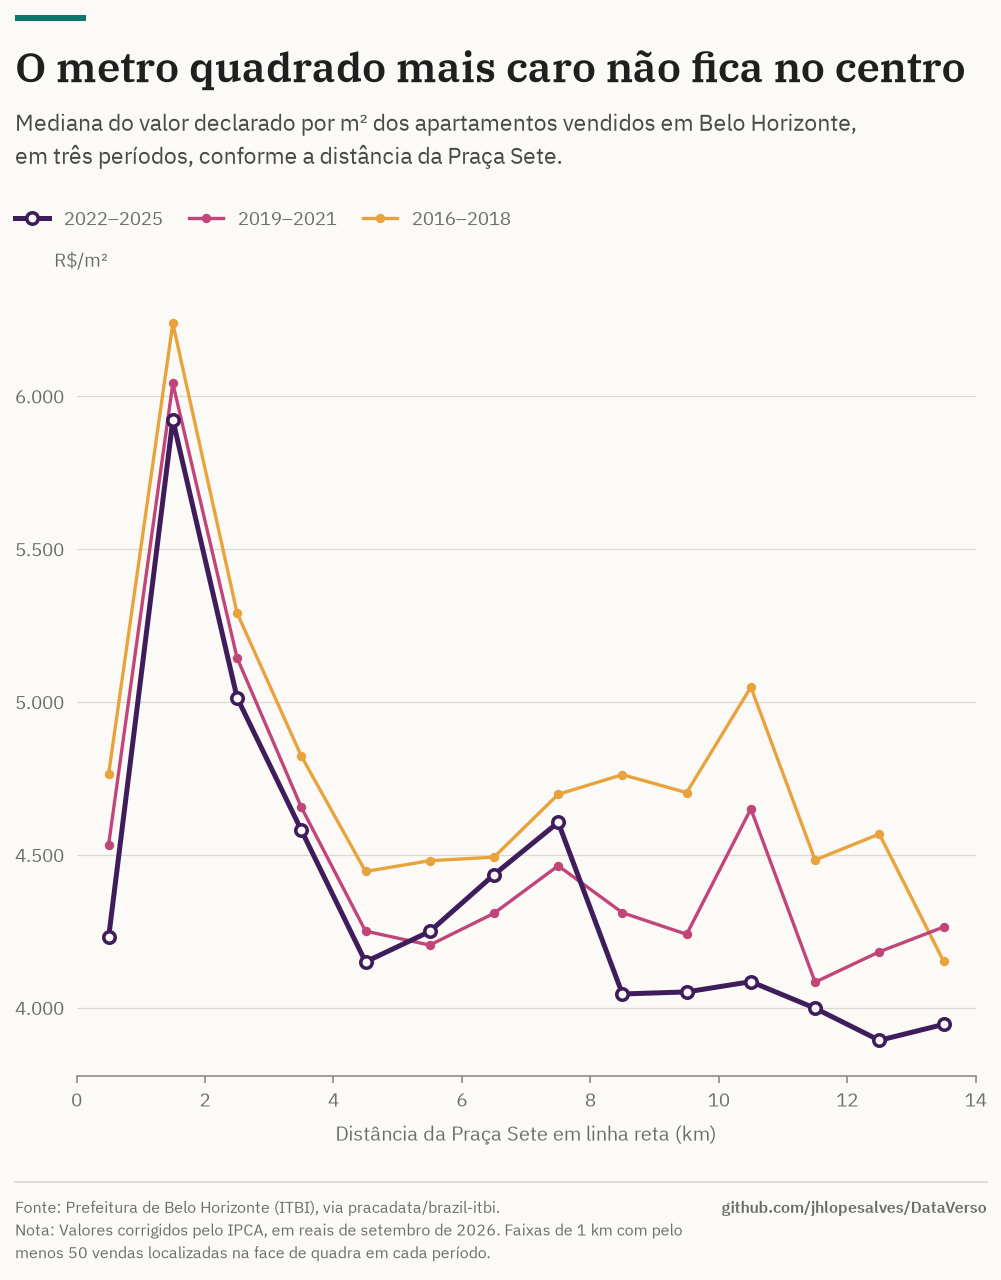

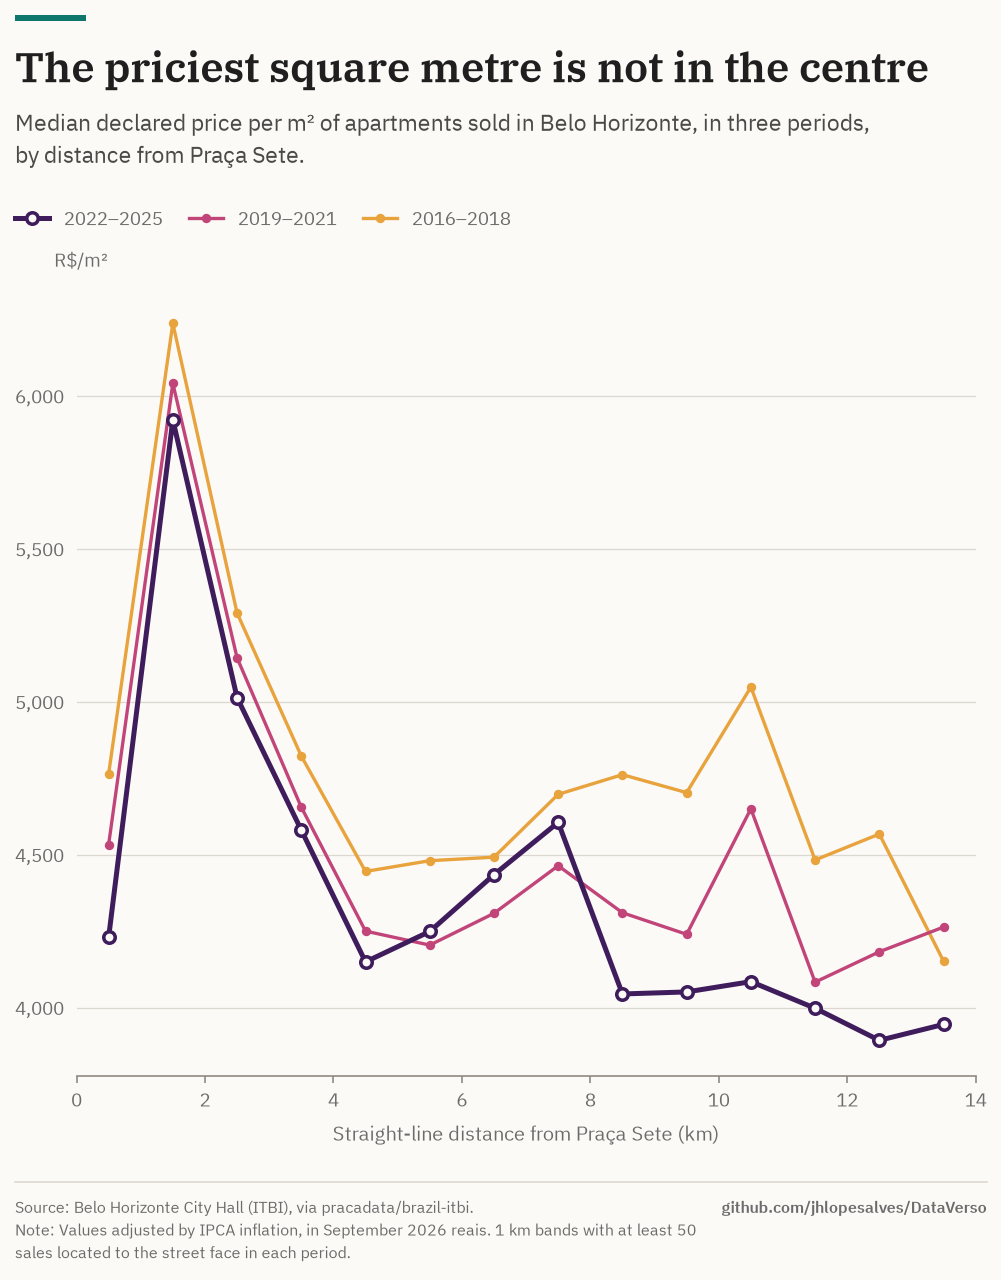

In [12]:
# The title says the priciest square metre is not in the centre, so in every period the band
# with the highest median must lie beyond the first band
for period, medians in gradient["median"].groupby(level="period"):
    medians = medians.droplevel("period")
    assert medians.idxmax() != medians.index[0], (
        f"{period}: the first band has the highest median"
    )

# Line style of each period, oldest first. Colour runs from amber to deep plum, so the order
# of the periods reads in the colour; the older periods also have thinner lines and small
# solid markers, and the latest hollow markers (paper-coloured faces, edges in its colour)
PERIOD_COLOURS = ("#e8a33d", "#c2457a", "#3f1d5c")
older_period = {"linewidth": 1.6, "marker": "o", "markersize": 3.5}
latest_period = {
    "linewidth": 2.4,
    "marker": "o",
    "markersize": 5.5,
    "markerfacecolor": PAPER,
    "markeredgewidth": 1.7,
}
period_style = {
    period: {"color": colour, **style}
    for period, colour, style in zip(
        period_names,
        PERIOD_COLOURS,
        [older_period, older_period, latest_period],
        strict=True,
    )
}

GRADIENT_TEXT = {
    "pt": {
        "title": "O metro quadrado mais caro não fica no centro",
        "subtitle": (
            "Mediana do valor declarado por m² dos apartamentos vendidos em Belo Horizonte,\n"
            "em três períodos, conforme a distância da Praça Sete."
        ),
        "unit": "R$/m²",
        "xlabel": "Distância da Praça Sete em linha reta (km)",
        "note": (
            "Valores corrigidos pelo IPCA, em reais de setembro de 2026. Faixas de 1 km com pelo\n"
            f"menos {MIN_SALES_PER_BAND} vendas localizadas na face de quadra em cada período."
        ),
    },
    "en": {
        "title": "The priciest square metre is not in the centre",
        "subtitle": (
            "Median declared price per m² of apartments sold in Belo Horizonte, in three periods,\n"
            "by distance from Praça Sete."
        ),
        "unit": "R$/m²",
        "xlabel": "Straight-line distance from Praça Sete (km)",
        "note": (
            f"Values adjusted by IPCA inflation, in September 2026 reais. 1 km bands with at least {MIN_SALES_PER_BAND}\n"
            "sales located to the street face in each period."
        ),
    },
}
for lang in LANGUAGES:
    text = GRADIENT_TEXT[lang]
    fig, ax = plt.subplots(figsize=SOCIAL_SIZE)
    frame(
        fig,
        title=text["title"],
        subtitle=text["subtitle"],
        source=SOURCE[lang],
        note=text["note"],
        lang=lang,
    )

    # One line of band medians per period, oldest first, so the latest is drawn on top
    for period in period_names:
        medians = gradient.loc[period, "median"]
        ax.plot(medians.index, medians, **period_style[period])

    # The key names the periods, newest first; the proxies repeat each line's style
    newest_first = period_names[::-1]
    add_key(
        ax,
        [Line2D([], [], **period_style[period]) for period in newest_first],
        newest_first,
    )

    # The axis starts at about R$ 3,800, not zero, so the baseline stays ligh
    style_axes(ax, text["unit"], xlabel=text["xlabel"])
    ax.set_xlim(0, MAX_DISTANCE_KM)
    ax.set_xticks(range(0, MAX_DISTANCE_KM + 1, 2))
    ax.yaxis.set_major_formatter(number_formatter(lang))

    fig.savefig(OUTPUT_DIR / f"02_distance_gradient_{lang}.png")
    plt.show()

## 5. How did recorded values change after adjustment?

The raw median reflects both the values and the mix of properties sold in a given year. A hedonic regression estimates changes in recorded values after adjusting for the property characteristics in the model:

$$\log p_i = \alpha + \beta \log a_i + \gamma_{\text{age}(i)} + \delta_{\text{type}(i)} + \mu_{\text{neighbourhood}(i)} + \tau_{\text{year}(i)} + \varepsilon_i$$

where $p_i$ is the inflation-adjusted declared value or ITBI tax base per m² of sale $i$ and $a_i$ its built area. The year effects $\tau_t$ are log differences from 2016 for properties of the same size, age band, type and neighbourhood, so $100\,e^{\tau_t}$ is a characteristics-adjusted index with 2016 = 100. Standard errors are clustered by neighbourhood, and only neighbourhoods with at least 100 sales are kept, so each neighbourhood effect rests on enough data.

The model is fitted twice, on two measures of value. The **declared value** is what the parties reported. The **tax base** is the value used to calculate ITBI. The two series can move differently as the relationship between the recorded values changes over time (section 3.2).

In [13]:
# Sales with a known building age, in neighbourhoods with enough sales to
# estimate a neighbourhood effect
hedonic_data = residential.dropna(subset=["building_age_band"]).copy()
hedonic_data = hedonic_data.loc[
    hedonic_data.groupby("neighbourhood")["neighbourhood"].transform("size")
    >= MIN_SALES_PER_NEIGHBOURHOOD
]

# The dataset deflates only the declared value, so the same monthly IPCA factor
# is recovered from it and applied to the tax base
deflator = hedonic_data["value_declared_brl_real"] / hedonic_data["value_declared_brl"]
hedonic_data["declared_m2_real"] = hedonic_data["price_per_m2_brl_real"]
hedonic_data["tax_base_m2_real"] = (
    hedonic_data["value_tax_base_brl"] * deflator / hedonic_data["built_area_m2"]
)
# Integer code per neighbourhood, used to cluster the standard errors
neighbourhood_codes = hedonic_data["neighbourhood"].astype("category").cat.codes

# Fit the same model on each value measure and turn its year effects into an index
hedonic_models = {}
index_parts = []
for measure, column in MEASURES.items():
    model = smf.ols(FORMULA.format(value=column), data=hedonic_data).fit(
        cov_type="cluster", cov_kwds={"groups": neighbourhood_codes}
    )
    hedonic_models[measure] = model

    # Year coefficients are log differences from 2016; exp() turns them into an index
    year_terms = model.params.filter(like="C(year)").index
    estimates = pd.concat(
        [model.params[year_terms], model.conf_int().loc[year_terms]], axis=1
    )
    part = (100 * np.exp(estimates)).set_axis(["hedonic", "lower", "upper"], axis=1)
    part.index = year_terms.str.extract(r"(\d{4})")[0].astype(int)
    part.loc[START_YEAR] = 100.0

    # The raw median of the same sales, on the same 2016 = 100 scale, for comparison
    raw_median = hedonic_data.groupby("year")[column].median()
    part["raw_median"] = 100 * raw_median / raw_median[START_YEAR]
    index_parts.append(part.sort_index().assign(measure=measure))

    print(
        f"{measure}: {int(model.nobs):,} sales, "
        f"{hedonic_data['neighbourhood'].nunique()} neighbourhoods, R² = {model.rsquared:.3f}"
    )

# One long table (measure, year, index values), shown wide for reading
price_index = pd.concat(index_parts).rename_axis("year").reset_index()
display(
    price_index.pivot(
        index="year", columns="measure", values=["raw_median", "hedonic"]
    ).style.format("{:.1f}")
)

Declared value: 202,204 sales, 192 neighbourhoods, R² = 0.236
Tax base: 202,204 sales, 192 neighbourhoods, R² = 0.466


The characteristics-adjusted index for declared values reaches 115.4 in 2025 (2016 = 100). The corresponding ITBI tax-base index falls to 87.0 in 2022 and reaches 97.9 in 2025 (95% CI 95.8–100.1). In the model sample, the share of declared values below the tax base falls from about 69% in 2016 to about 24% in 2024. This convergence helps explain why the two measures tell different stories.

In 2025 the raw medians, also indexed to 2016, are 98.1 for declared values and 90.6 for the tax base. The share of new buildings in the model sample falls from 36% in 2016 to 20% in 2025, and the share aged 26 years or more rises from 22% to 37%. The breakdown below measures how much of the gap between the tax-base index and its raw average that shift explains. It uses the geometric mean of the sales rather than their median, because the mean of the logs splits exactly into the model's terms. In 2025 the raw geometric mean is 4.6 log points below the index. The building-age bands account for 6.2 points, more than the whole gap, while the neighbourhood mix offsets 1.6 points and area with property type 0.1.

In [14]:
# Share of each building-age band among the year's sales
composition = pd.crosstab(
    hedonic_data["year"], hedonic_data["building_age_band"], normalize="index"
)[["new", "3_10", "11_25", "26_plus"]]
# Share of the year's sales declared below the tax base (R$ 1 tolerance).
composition["declared below tax base"] = (
    (hedonic_data["value_declared_brl"] < hedonic_data["value_tax_base_brl"] - 1)
    .groupby(hedonic_data["year"])
    .mean()
)
display(composition.style.format("{:.1%}"))

building_age_band,new,3_10,11_25,26_plus,declared below tax base
year,,,,,
2016,36.0%,21.8%,20.6%,21.6%,68.9%
2017,30.9%,24.0%,22.1%,23.1%,72.6%
2018,28.2%,26.3%,21.9%,23.6%,69.5%
2019,21.8%,30.9%,22.9%,24.4%,66.4%
2020,21.0%,29.4%,24.3%,25.3%,54.4%
2021,21.5%,27.0%,25.8%,25.8%,45.5%
2022,21.3%,22.6%,26.0%,30.1%,35.2%
2023,20.6%,20.9%,26.7%,31.8%,27.0%
2024,20.8%,17.3%,28.0%,33.9%,24.3%


### Splitting the gap between the raw average and the index

The model has an intercept and a year effect for every year, so its residuals average zero within each year. The change in the mean log tax base since 2016 therefore splits exactly into the year effect and the change in the mean of each column of the design matrix, weighted by its estimated coefficient $\hat\theta_k$:

$$\overline{\log p}_t - \overline{\log p}_{2016} = \tau_t + \sum_{g} \sum_{k \in g} \hat\theta_k\,(\bar x_{k,t} - \bar x_{k,2016})$$

The left side is the change in the geometric mean of the sales in the model, the raw average of the figure. The groups $g$ are the building-age bands, the neighbourhoods, and area with property type, whose terms stay below half a log point in every year. The next cell checks the identity and lists the terms in log points. The figure converts them to index points with the logarithmic mean of the raw average and the index, $(R_t - I_t) / \ln(R_t / I_t)$, which keeps each term's sign and share and makes the bands add up to the gap between the lines exactly.

In [15]:
# The tax-base model's own design matrix and outcome, so the breakdown covers exactly the sales
# behind the index
tax_model = hedonic_models["Tax base"]
design = pd.DataFrame(tax_model.model.exog, columns=tax_model.model.exog_names)
log_tax_base = pd.Series(tax_model.model.endog)
sale_year = hedonic_data.loc[tax_model.model.data.row_labels, "year"].to_numpy()

# Design columns by group. The intercept is the same in every year, so it drops out of any
# change from 2016 and is the one column left out
columns = design.columns
groups = {
    "year": columns[columns.str.startswith("C(year)")],
    "age": columns[columns.str.contains("building_age_band")],
    "neighbourhood": columns[columns.str.startswith("C(neighbourhood)")],
    "area_type": columns[
        columns.str.startswith(("np.log(built_area_m2)", "C(property_type)"))
    ],
}
assert sum(map(len, groups.values())) == len(columns) - 1, (
    "a design column has no group"
)
PARTS = ["age", "neighbourhood", "area_type"]  # every group but the year effects

# Each column's change in mean since 2016, weighted by its coefficient and summed by group
mean_change = design.groupby(sale_year).mean()
mean_change -= mean_change.loc[START_YEAR]
contribution = pd.DataFrame(
    {
        group: mean_change[cols] @ tax_model.params[cols]
        for group, cols in groups.items()
    }
)

# The raw average is the geometric mean of the same sales, exp(mean of the log), so its change
# from 2016 in logs is the change in the mean log. The index is 100 * exp(year effect)
mean_log = log_tax_base.groupby(sale_year).mean()
raw_change = mean_log - mean_log.loc[START_YEAR]
tax_index = price_index.loc[price_index["measure"] == "Tax base"].set_index("year")
index_change = np.log(tax_index["hedonic"] / 100)

# OLS with an intercept and year effects leaves residuals that average zero in each year, so
# the raw change is the year effect plus the contributions, up to rounding error
gap_log = contribution[PARTS].sum(axis=1)
identity_error = (raw_change - index_change - gap_log).abs().max()
print(f"Largest identity error: {identity_error:.1e}")
assert identity_error < 1e-9, (
    "the index is estimated in a way the breakdown does not cover"
)

# Plotted values: the raw average on the index scale, and each contribution in index points
# Scaling the log terms by the logarithmic mean of raw and index, I * (exp(gap) - 1) / gap,
# keeps their signs and shares and makes them add up to the gap between the lines exactly;
# with no gap, the logarithmic mean is the index itself
tax_index["raw_average"] = 100 * np.exp(raw_change)
log_mean = tax_index["hedonic"] * (
    np.expm1(gap_log) / gap_log.where(gap_log != 0)
).fillna(1)
gap_points = contribution[PARTS].mul(log_mean, axis=0)
assert np.allclose(
    gap_points.sum(axis=1), tax_index["raw_average"] - tax_index["hedonic"]
)

# In log points the raw change is the index plus the three contributions; in index points the
# raw average is the index plus the three bands
log_points = 100 * pd.concat(
    [index_change.rename("index"), raw_change.rename("raw"), contribution[PARTS]],
    axis=1,
)
index_points = pd.concat(
    [
        tax_index["hedonic"].rename("index"),
        tax_index["raw_average"].rename("raw"),
        gap_points,
    ],
    axis=1,
)
display(
    pd.concat({"Log points × 100": log_points, "Index points": index_points}, axis=1)
    .rename_axis("year")
    .style.format("{:.2f}")
)

Largest identity error: 2.0e-14


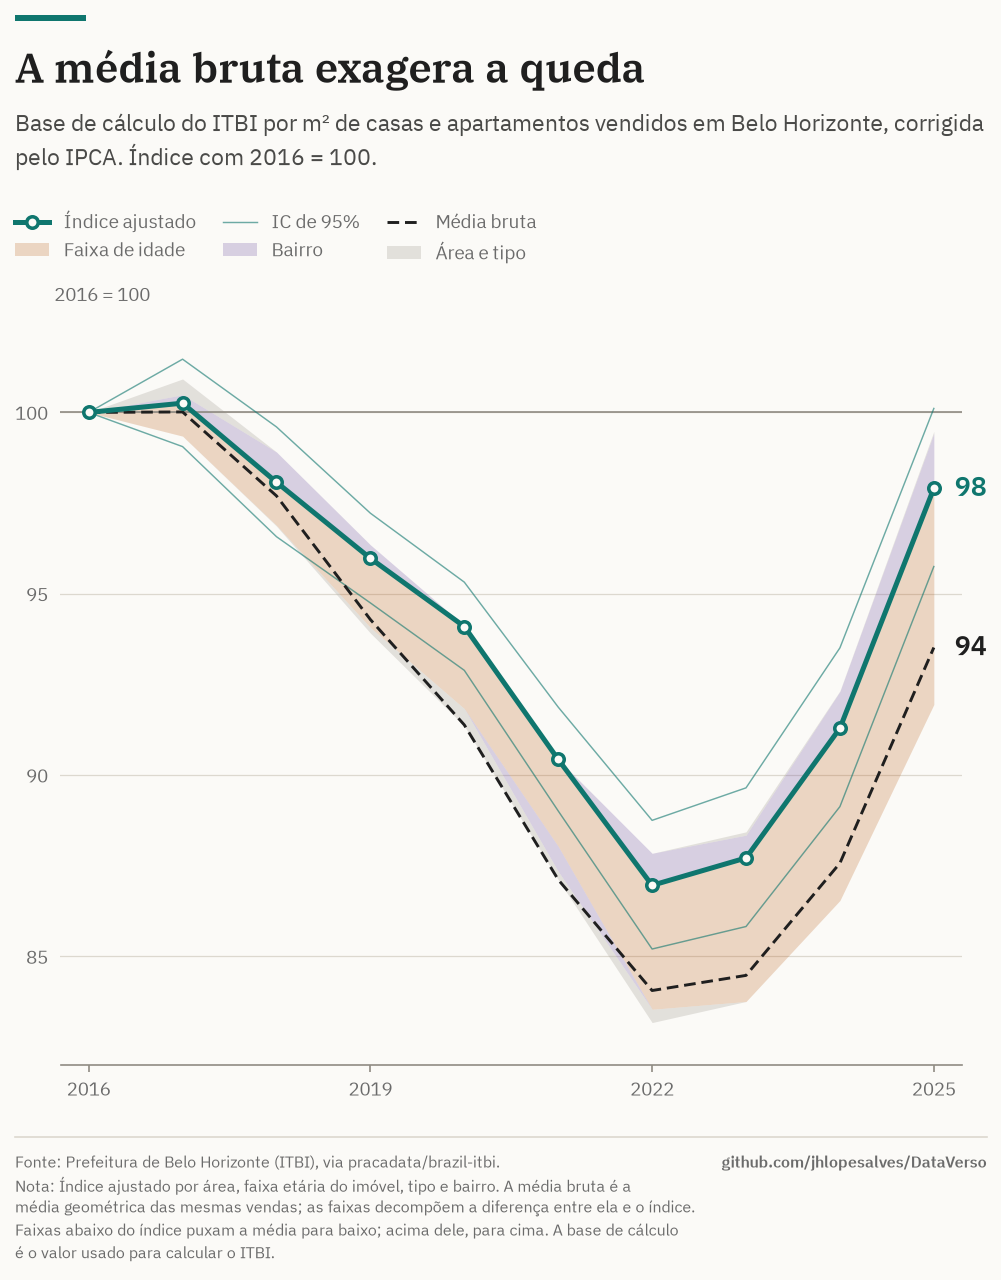

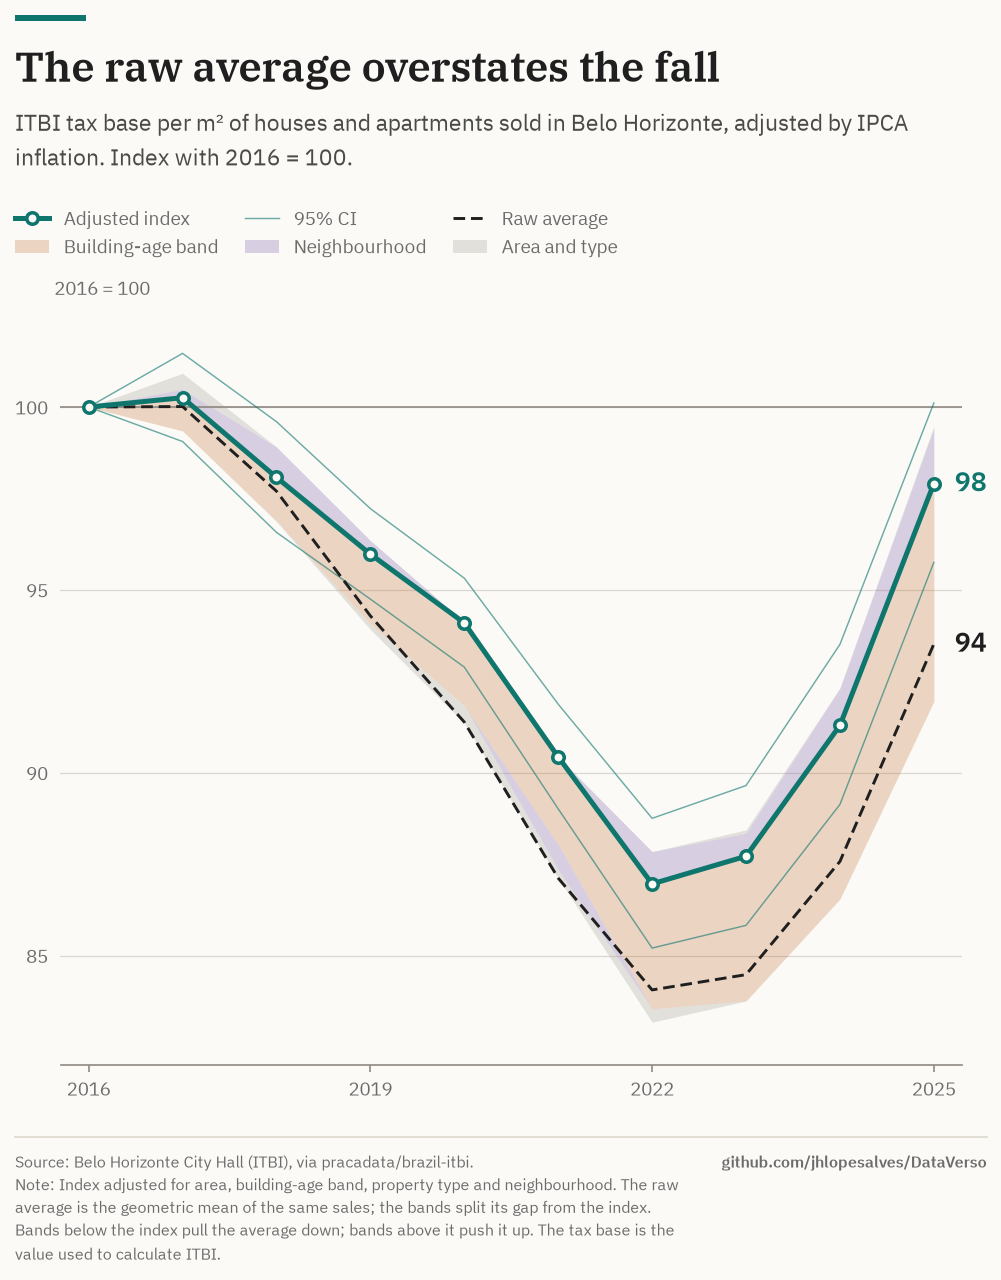

In [16]:
# The post figure uses the tax base; its title describes that result, so the
# texts below need rewriting if the measure is ever changed.
index = tax_index
last = index.loc[END_YEAR]

# The title says the raw average overstates the fall, so it must lie below the index in every
# year after 2016
later = index.index > START_YEAR
assert (index.loc[later, "raw_average"] < index.loc[later, "hedonic"]).all(), (
    "the raw average is not below the index in every year after 2016"
)

# Bands, from the index outwards: building age in amber, neighbourhood in violet, and area
# with property type in grey (colour, opacity)
BANDS = {
    "age": ("#b45309", 0.22),
    "neighbourhood": ("#6d4fa3", 0.25),
    "area_type": (CONTEXT, 0.35),
}

# Styles shared by the lines and their proxies in the key. The raw average is dashed and
# dark, so it stays legible where it runs across a band
index_style = {
    "color": ACCENT,
    "linewidth": 2.4,
    "marker": "o",
    "markersize": 5.5,
    "markerfacecolor": PAPER,
    "markeredgewidth": 1.7,
}
interval_style = {"color": ACCENT, "linewidth": 0.7, "alpha": 0.6}
raw_style = {"color": INK, "linewidth": 1.4, "linestyle": (0, (4, 2))}

INDEX_TEXT = {
    "pt": {
        "title": "A média bruta exagera a queda",
        "subtitle": (
            "Base de cálculo do ITBI por m² de casas e apartamentos vendidos em Belo Horizonte, corrigida\n"
            f"pelo IPCA. Índice com {START_YEAR} = 100."
        ),
        "unit": f"{START_YEAR} = 100",
        "index": "Índice ajustado",
        "interval": "IC de 95%",
        "raw": "Média bruta",
        "age": "Faixa de idade",
        "neighbourhood": "Bairro",
        "area_type": "Área e tipo",
        "note": (
            "Índice ajustado por área, faixa etária do imóvel, tipo e bairro. A média bruta é a\n"
            "média geométrica das mesmas vendas; as faixas decompõem a diferença entre ela e o índice.\n"
            "Faixas abaixo do índice puxam a média para baixo; acima dele, para cima. A base de cálculo\n"
            "é o valor usado para calcular o ITBI."
        ),
    },
    "en": {
        "title": "The raw average overstates the fall",
        "subtitle": (
            "ITBI tax base per m² of houses and apartments sold in Belo Horizonte, adjusted by IPCA\n"
            f"inflation. Index with {START_YEAR} = 100."
        ),
        "unit": f"{START_YEAR} = 100",
        "index": "Adjusted index",
        "interval": "95% CI",
        "raw": "Raw average",
        "age": "Building-age band",
        "neighbourhood": "Neighbourhood",
        "area_type": "Area and type",
        "note": (
            "Index adjusted for area, building-age band, property type and neighbourhood. The raw\n"
            "average is the geometric mean of the same sales; the bands split its gap from the index.\n"
            "Bands below the index pull the average down; bands above it push it up. The tax base is the\n"
            "value used to calculate ITBI."
        ),
    },
}

for lang in LANGUAGES:
    text = INDEX_TEXT[lang]
    fig, ax = plt.subplots(figsize=SOCIAL_SIZE)
    frame(
        fig,
        title=text["title"],
        subtitle=text["subtitle"],
        source=SOURCE[lang],
        note=text["note"],
        lang=lang,
    )

    # The 2016 level, slightly darker than the grid, as the line of reference
    ax.axhline(100, color=AXIS, linewidth=0.8)

    # Each contribution is a band stacked outwards from the index: below it when it pulls the
    # raw average down, above it when it pushes it up. Stacking each sign on its own side
    # keeps the bands from overlapping, and the raw average runs through them at the net
    below, above = index["hedonic"].copy(), index["hedonic"].copy()
    for part, (colour, alpha) in BANDS.items():
        down, up = gap_points[part].clip(upper=0), gap_points[part].clip(lower=0)
        ax.fill_between(
            index.index, below + down, below, color=colour, alpha=alpha, linewidth=0
        )
        ax.fill_between(
            index.index, above, above + up, color=colour, alpha=alpha, linewidth=0
        )
        below, above = below + down, above + up

    # The lines on top: the index in the accent colour, with hollow markers, between the two
    # thin lines of its confidence interval, and the raw average
    for bound in ("lower", "upper"):
        ax.plot(index.index, index[bound], **interval_style)
    ax.plot(index.index, index["raw_average"], **raw_style)
    ax.plot(index.index, index["hedonic"], **index_style)

    # Each line ends in its final value, in its own colour; the key names the lines
    for column, colour in [("hedonic", ACCENT), ("raw_average", INK)]:
        ax.annotate(
            f"{last[column]:.0f}",
            (END_YEAR, last[column]),
            xytext=(10, 0),
            textcoords="offset points",
            va="center",
            fontsize=13,
            fontweight="semibold",
            color=colour,
        )

    # The key, in the order of the data from top to bottom. With three columns the legend
    # fills each column downwards, so the handles are interleaved to read as two rows: the lines, then the bands
    lines = [
        (Line2D([], [], **index_style), text["index"]),
        (Line2D([], [], **interval_style), text["interval"]),
        (Line2D([], [], **raw_style), text["raw"]),
    ]
    bands = [
        (Patch(facecolor=colour, alpha=alpha, linewidth=0), text[part])
        for part, (colour, alpha) in BANDS.items()
    ]
    interleaved = [entry for pair in zip(lines, bands, strict=True) for entry in pair]
    handles, labels = zip(*interleaved, strict=True)
    add_key(ax, handles, labels, ncols=3)

    # The axis does not start at zero, so the baseline stays light
    style_axes(ax, text["unit"])
    ax.set_xticks(range(START_YEAR, END_YEAR + 1, 3))
    ax.set_xlim(START_YEAR - 0.3, END_YEAR + 0.3)
    ax.set_yticks(range(85, 101, 5))
    ax.set_ylim(82, 102.5)

    fig.savefig(OUTPUT_DIR / f"03_price_index_{lang}.png")
    plt.show()

## 6. Clustering at round declared values

For 2023–2025, the analysis groups nominal declared values from R$55,000 to under R$1,045,000 into R$10,000 bins. A round bin is centred on an exact multiple of R$50,000. The share of declarations at those exact values and the share within the round bins are both observed directly.

To estimate excess clustering, a Poisson regression with a natural cubic spline is fitted to the non-round bins. Its predictions are then rescaled to the total observed count across all bins. The lower panel measures the percentage by which each round bin exceeds this fitted reference.

With seven spline degrees of freedom, the round bins contain 30.50% of sales against a fitted share of 19.84%. Using five or nine degrees of freedom gives fitted shares of 19.76% and 19.86%, respectively. The aggregate excess is similar across these fits, while estimates for individual bins vary with the smooth curve.

In [17]:
BUNCH_YEARS = (2023, 2025)
BUNCH_BIN = 10_000  # bin width, in reais
ROUND_STEP = 50_000  # a bin is round when its centre is a multiple of this
BUNCH_RANGE = (
    55_000,
    1_045_000,
)  # from, up to but excluding: bins centred on R$ 60 mil to R$ 1.04 million
SPLINE_DF = 7  # flexibility of the smooth expected curve

# Recent sales with a declared value inside the range covered by the bins
bunch_sales = residential.loc[
    residential["year"].between(*BUNCH_YEARS)
    & residential["value_declared_brl"].between(*BUNCH_RANGE, inclusive="left")
]
values = bunch_sales["value_declared_brl"]

# Count the sales in bins centred on multiples of BUNCH_BIN. floor(x + 0.5)
# sends every half-way value to the bin above it; round() would send it to the nearest even bin and favour some bins over others.
bunching = (
    (np.floor(values / BUNCH_BIN + 0.5) * BUNCH_BIN)
    .astype(int)
    .value_counts()
    .sort_index()
    .rename_axis("value")
    .reset_index(name="observed")
)
bunching["is_round"] = bunching["value"] % ROUND_STEP == 0

# Expected counts: a smooth curve fitted only to the bins that are not round,
# then rescaled so that expected and observed totals match. The uncentred
# spline basis already spans the constant, so omit the separate intercept
smooth_model = smf.glm(
    f"observed ~ 0 + cr(value, df={SPLINE_DF})",
    data=bunching.loc[~bunching["is_round"]],
    family=sm.families.Poisson(),
).fit()
bunching["expected"] = smooth_model.predict(bunching)
bunching["expected"] *= bunching["observed"].sum() / bunching["expected"].sum()
bunching["excess"] = bunching["observed"] / bunching["expected"] - 1
round_bins = bunching.loc[bunching["is_round"]]

# Three summaries: exact round values, and round bins observed against expected
exact_share = (values % ROUND_STEP == 0).mean()
observed_share = round_bins["observed"].sum() / bunching["observed"].sum()
expected_share = round_bins["expected"].sum() / bunching["expected"].sum()

print(f"{len(values):,} sales in {len(bunching)} bins, {len(round_bins)} of them round")
print(f"Declared at an exact multiple of R$ {ROUND_STEP:,}: {exact_share:.1%}")
print(
    f"Share of sales in round bins: {observed_share:.1%} observed, {expected_share:.1%} expected"
)
display(
    round_bins.set_index("value")
    .drop(columns="is_round")
    .style.format({"observed": "{:,}", "expected": "{:,.0f}", "excess": "{:+.0%}"})
)

58,177 sales in 99 bins, 19 of them round
Declared at an exact multiple of R$ 50,000: 22.1%
Share of sales in round bins: 30.5% observed, 19.8% expected


,observed,expected,excess
value,,,
100000,420,324,+29%
150000,962,696,+38%
200000,"1,487","1,207",+23%
250000,"2,056","1,519",+35%
300000,"1,873","1,422",+32%
350000,"2,074","1,138",+82%
400000,"1,312",898,+46%
450000,"1,075",753,+43%
500000,"1,130",654,+73%


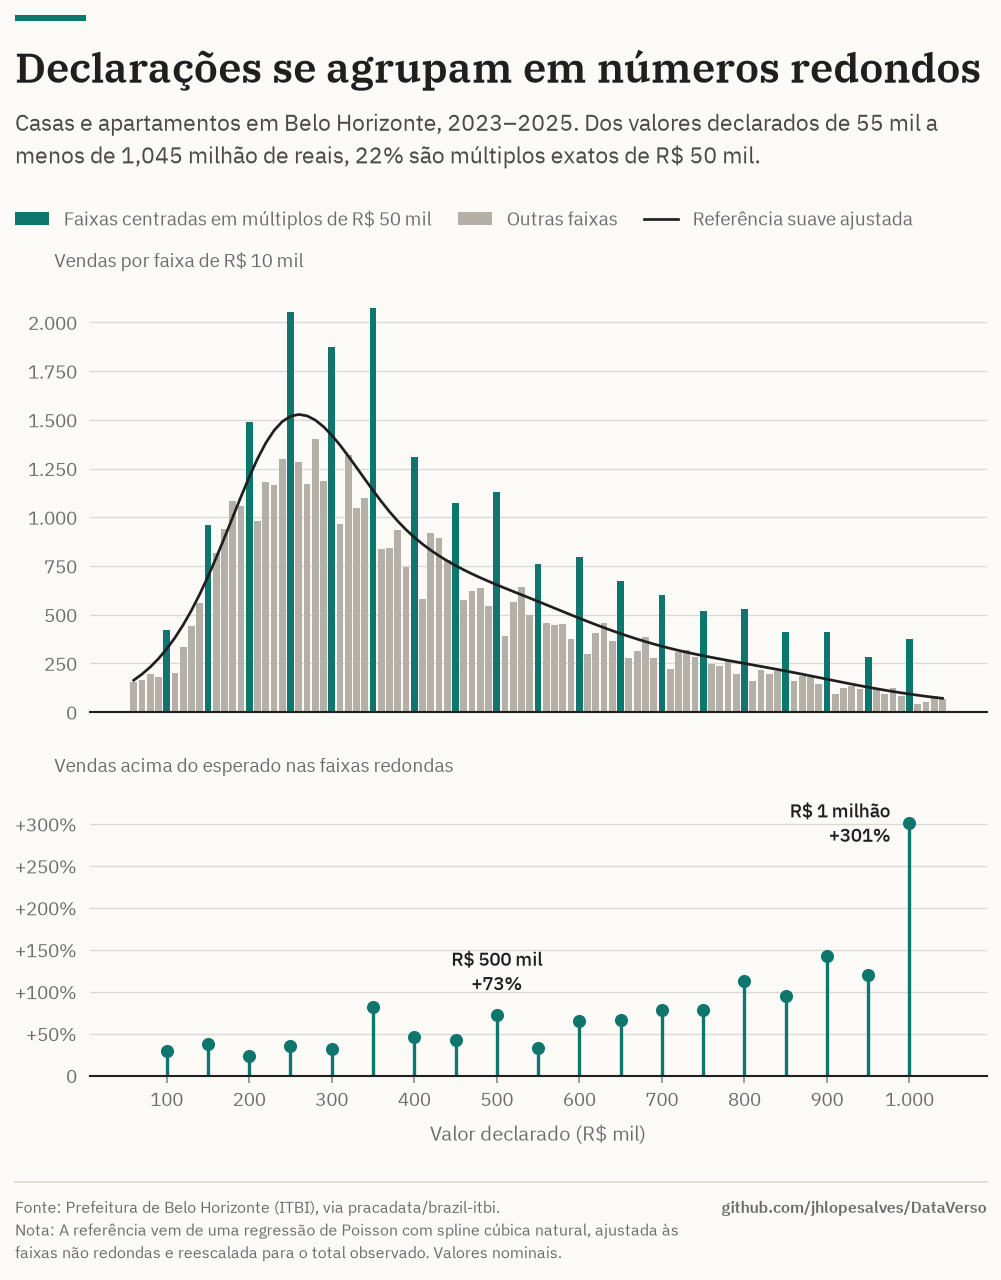

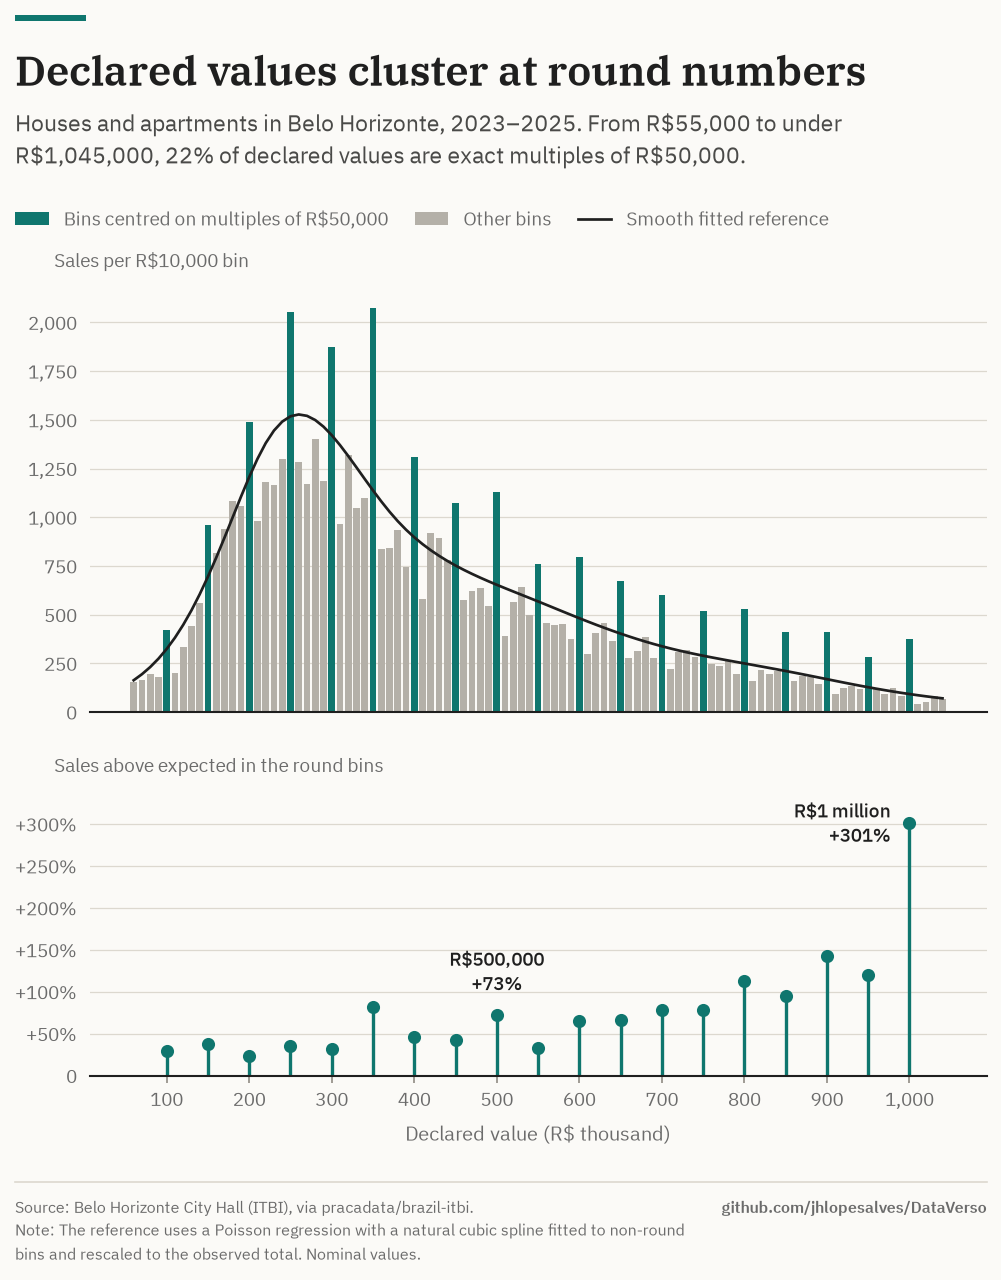

In [18]:
# The two round values that get a label in the lower panel, and where each
# label sits relative to its point (offset in points, alignment)
LABELLED = {
    500_000: {
        "pt": "R$ 500 mil",
        "en": "R$500,000",
        "place": {"xytext": (0, 9), "ha": "center", "va": "bottom"},
    },
    1_000_000: {
        "pt": "R$ 1 milhão",
        "en": "R$1 million",
        "place": {"xytext": (-9, 0), "ha": "right", "va": "center"},
    },
}

BUNCH_TEXT = {
    "pt": {
        "title": "Declarações se agrupam em números redondos",
        "subtitle": (
            f"Casas e apartamentos em Belo Horizonte, {BUNCH_YEARS[0]}–{BUNCH_YEARS[1]}. Dos valores declarados de 55 mil a\n"
            f"menos de 1,045 milhão de reais, {exact_share:.0%} são múltiplos exatos de R$ 50 mil."
        ),
        "unit_top": "Vendas por faixa de R$ 10 mil",
        "unit_bottom": "Vendas acima do esperado nas faixas redondas",
        "round": "Faixas centradas em múltiplos de R$ 50 mil",
        "other": "Outras faixas",
        "expected": "Referência suave ajustada",
        "xlabel": "Valor declarado (R$ mil)",
        "note": (
            "A referência vem de uma regressão de Poisson com spline cúbica natural, ajustada às\n"
            "faixas não redondas e reescalada para o total observado. Valores nominais."
        ),
    },
    "en": {
        "title": "Declared values cluster at round numbers",
        "subtitle": (
            f"Houses and apartments in Belo Horizonte, {BUNCH_YEARS[0]}–{BUNCH_YEARS[1]}. From R$55,000 to under\n"
            f"R$1,045,000, {exact_share:.0%} of declared values are exact multiples of R$50,000."
        ),
        "unit_top": "Sales per R$10,000 bin",
        "unit_bottom": "Sales above expected in the round bins",
        "round": "Bins centred on multiples of R$50,000",
        "other": "Other bins",
        "expected": "Smooth fitted reference",
        "xlabel": "Declared value (R$ thousand)",
        "note": (
            "The reference uses a Poisson regression with a natural cubic spline fitted to non-round\n"
            "bins and rescaled to the observed total. Nominal values."
        ),
    },
}

# Values are plotted in thousands of reais
x = bunching["value"] / 1_000
x_round = round_bins["value"] / 1_000

for lang in LANGUAGES:
    text = BUNCH_TEXT[lang]
    # Two stacked panels sharing the x axis, then the header and footer around them
    fig, (ax_counts, ax_excess) = plt.subplots(
        2, 1, figsize=SOCIAL_SIZE, sharex=True, height_ratios=[3, 2]
    )
    frame(
        fig,
        title=text["title"],
        subtitle=text["subtitle"],
        source=SOURCE[lang],
        note=text["note"],
        lang=lang,
    )

    # Upper panel: observed counts as bars (round bins in the accent colour) and the expected counts as a line
    ax_counts.bar(
        x,
        bunching["observed"],
        width=BUNCH_BIN / 1_000 * 0.82,
        color=np.where(bunching["is_round"], ACCENT, CONTEXT),
    )
    ax_counts.plot(x, bunching["expected"], color=INK, linewidth=1.3)

    # Lower panel: how far each round bin sits above its expected count
    ax_excess.vlines(x_round, 0, round_bins["excess"], color=ACCENT, linewidth=1.6)
    ax_excess.scatter(x_round, round_bins["excess"], s=28, color=ACCENT, zorder=3)
    for value, names in LABELLED.items():
        excess = round_bins.set_index("value").loc[value, "excess"]
        ax_excess.annotate(
            f"{names[lang]}\n+{excess:.0%}",
            (value / 1_000, excess),
            textcoords="offset points",
            fontsize=9,
            fontweight="medium",
            color=INK,
            linespacing=1.3,
            **names["place"],
        )

    # The key names the two kinds of bin and the reference curve; the stems of the lower panel repeat the accent of the round bins
    add_key(
        ax_counts,
        [
            Patch(facecolor=ACCENT, linewidth=0),
            Patch(facecolor=CONTEXT, linewidth=0),
            Line2D([], [], color=INK, linewidth=1.3),
        ],
        [text["round"], text["other"], text["expected"]],
    )

    # Both panels start at zero, so both get the dark baseline
    style_axes(ax_counts, text["unit_top"], zero_baseline=True)
    style_axes(
        ax_excess, text["unit_bottom"], zero_baseline=True, xlabel=text["xlabel"]
    )
    ax_counts.tick_params(axis="x", labelbottom=False, length=0)
    ax_counts.yaxis.set_major_formatter(number_formatter(lang))
    ax_excess.yaxis.set_major_formatter(
        FuncFormatter(lambda v, _: f"+{v:.0%}" if v else "0")
    )
    ax_excess.set_ylim(0, round_bins["excess"].max() * 1.12)
    ax_excess.set_xticks(range(100, 1_001, 100))
    ax_excess.xaxis.set_major_formatter(number_formatter(lang))

    fig.savefig(OUTPUT_DIR / f"04_round_numbers_{lang}.png")
    plt.show()